In [86]:
%load_ext autoreload
%autoreload 2

import MonteCarloPricing
import Plotting 

import numpy as np
import matplotlib.pyplot as plt 
import scipy.stats as st

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<!-- To Do
- comapre euler and milstein and write nice text
- what are the exponents for strong and weak convergence
- why is there so much noise for euler weak convergence? Z = (Z-mean(Z))/std(Z) ? 
    - momwnt mathcing make explicit  -->

To do (later):
- Importance sampling 
- Greeks 
- check put pull parity
- check martingale property 

This notebook presents some functionalities of the MonteCarloPricing program, which uses Monte Carlo techniques to price options. 

We start by modeling stock prices by generating geometric brownian motion (GBM) paths under the risk-neutral meassure.
Two different path generating schemes are presented, that is the euler and milstein scheme.
The difference between simulated paths and the exact GBM solution for both schemes are then calculated. 
We place an emphasis on the convergence of simulated paths by varying different paramters. 

Next, we use these paths to calculate the price of a european call or put option, where simulated prices are comapred against the analytical Black-Scholes formula. Again we show the convergence of the simulates price to the anayltical one by increasing the number of considered paths. Errors and confidence intervals are presented graphically.


Let us introduce some notation
| Notation       | Explanation                     |
|---------|----------------------------------|
| $K$       | Strike Price                     |
| $T$       | Maturity                         |
| $r$ | interest rate                        |
| $M$       | number of time steps             |
| $N$       | number of paths                  |
| $S_i^{(j)}$ | asset price of path $j$ at time $i$  |
| $W_t$ | Wiener process                        |
| $\Delta t$ | time step                        |
| $V(i,S_i)$  | value of option at time $i$         |
| $\Phi(T,S_T)$  | payoff value at maturity with $\Phi(T,S_T)=V(T,S_T)$         |


Let's remind ourselfs the steps for the Monte Carlo algorithm of options pricing.

1. Partition the time interval $[0, T]$ into time steps $\Delta t=t_{i+1}-t_{i}$ with $i=1,\ldots,M$ and $t_i=T\frac{i}{M}$
2. Generate stock prices $S_i^{(j)}$ under the risk-neutral meassure, where $i$ denotes the time and $j=1,\ldots,N$ the path number 
3. Compute the payoff value $\Phi(T,S_T^j)$ at maturity $T$ for every path $j$
4. Calculate the option value at time $t_0$ as the discounted average under the risk-neutral meassure $$ \begin{align*} V(t_0, S_0) &= e^{−r(T −t_0)} \mathbb{E}^Q[\Phi(T)|\mathcal{F}(t_0)] \\
&=  e^{−r(T −t_0)}  \frac{1}{N} \sum_{j=1}^N \Phi(T,S_T^{(j)}) \end{align*}$$
5. Discuss standard deviation of above result


Consider a general price process 
$$ dS_t = \mu(t, S_t) dt + \sigma(t,S_t) dW_t$$
For an equidistant grid on $t_i\in [0,T]$ we have the solution 
$$ S_{i+1} = S_{i} + \int_{t_i}^{t_{i+1}} \mu(t, S_t) dt + \int_{t_i}^{t_{i+1}} \sigma(t, S_t) dW_t  

The dynamics of the GBM process under the risk-neutral meassure is governed by $dS_t = rS_t dt + \sigma S_t dW_t$. Its solution is given by $$ S(t_{i+1}) = S(t_i) \exp\Bigg(\Big(r −\frac{1}{2}\sigma^2\Big)\Delta t + \sigma \Big(W(t_{i+1}) − W(t_i)\Big)\Bigg) $$

First we introduce the Euler scheme, where the integrands are approximated by their values at the left-side boundary of the integration interval
$$  S_{i+1} \approx  S_{i} + \mu(t_i, S_i) (t_{i+1}-t_{i}) + \sigma(t_i, S_i) (W(t_{i+1})-W(t_i))   $$
Note that this is a linear approximation in the Brownian increment

The Milstein scheme includes an additional quadratic correction from the Itô–Taylor expansion
$$  S_{i+1} \approx  S_{i} + \mu(t_i, S_i) (t_{i+1}-t_{i}) + \sigma(t_i, S_i) (W(t_{i+1})-W(t_i))  +\frac{1}{2}\sigma \big((\Delta W_i)^2-\Delta t\big) \frac{\partial \sigma}{\partial S}$$

In [ ]:
paths_no = 2000
step_no = 1000
terminal_time = 1
interest_rate = 0.05
vol = 0.3
S_0 = 50

seed = 42



paths = {}
terminal_prices = {}

for scheme in ("euler", "milstein"):

    np.random.seed(seed)

    paths[scheme] = MonteCarloPricing.generate_GBM_paths(
        paths_no, step_no, terminal_time, interest_rate, vol, S_0, scheme
    )


    terminal_prices[scheme] = paths[scheme]["S_approx"][:, -1]

    print(
        f"{scheme} \n"
        f"Sample mean S(T): \t {np.mean(terminal_prices[scheme]):.4f}\n"
        f"Sample variance S(T): \t {np.var(terminal_prices[scheme], ddof=1):.4f}\n"
        f"Sample std S(T): \t {np.std(terminal_prices[scheme], ddof=1):.4f}"
        f"\n"
    )

euler 
Sample mean S(T): 	 52.1085
Sample variance S(T): 	 259.9649
Sample std S(T): 	 16.1234

milstein 
Sample mean S(T): 	 52.1135
Sample variance S(T): 	 260.1846
Sample std S(T): 	 16.1302



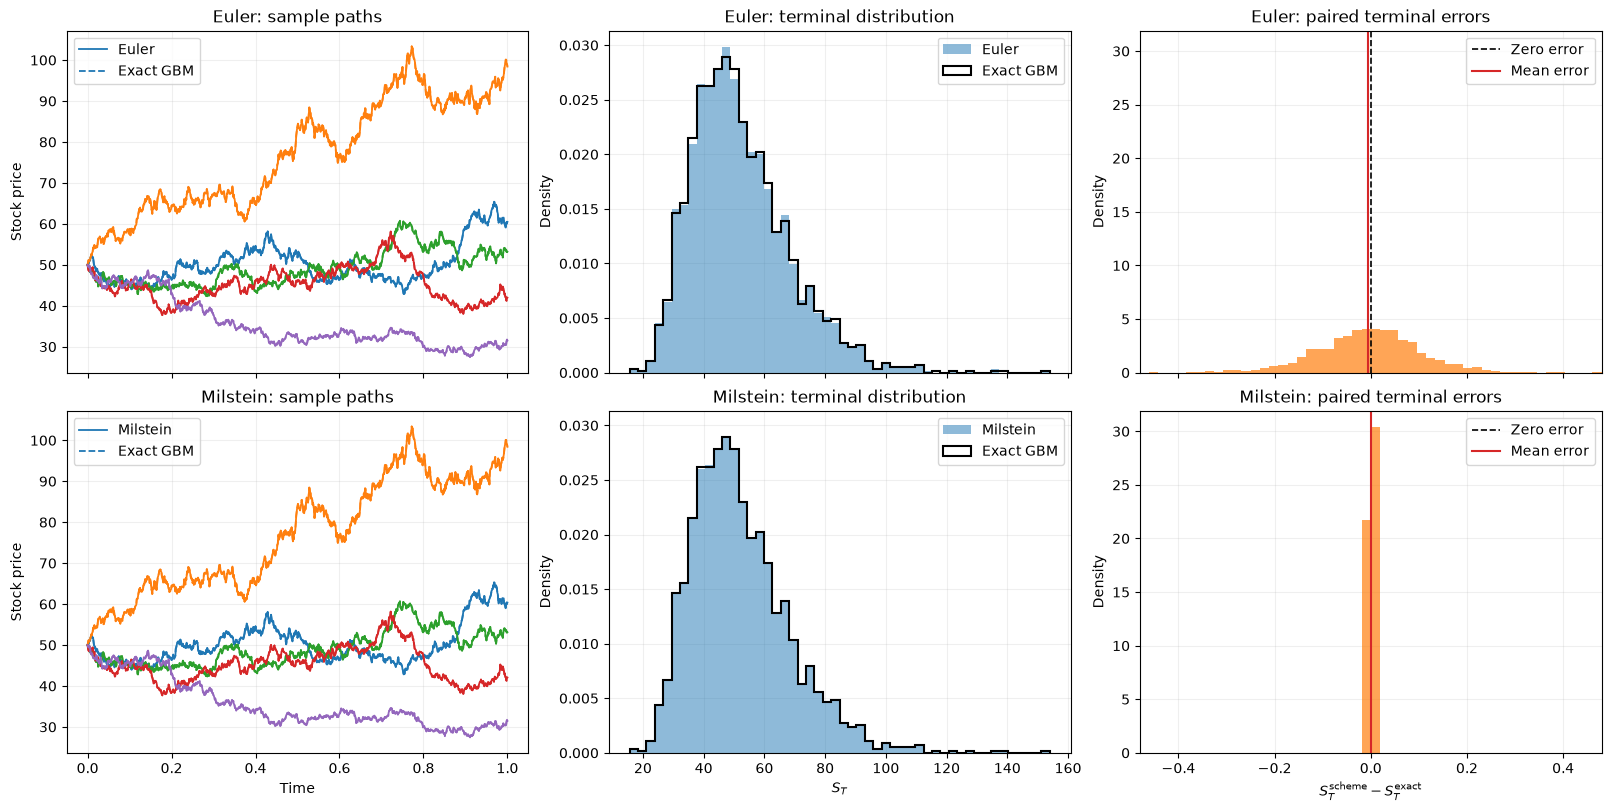

In [96]:
fig, axes = Plotting.plot_gbm_comparison(
    paths["euler"],
    paths["milstein"],
    paths_to_show=5,
    bins=50,
)

plt.show()

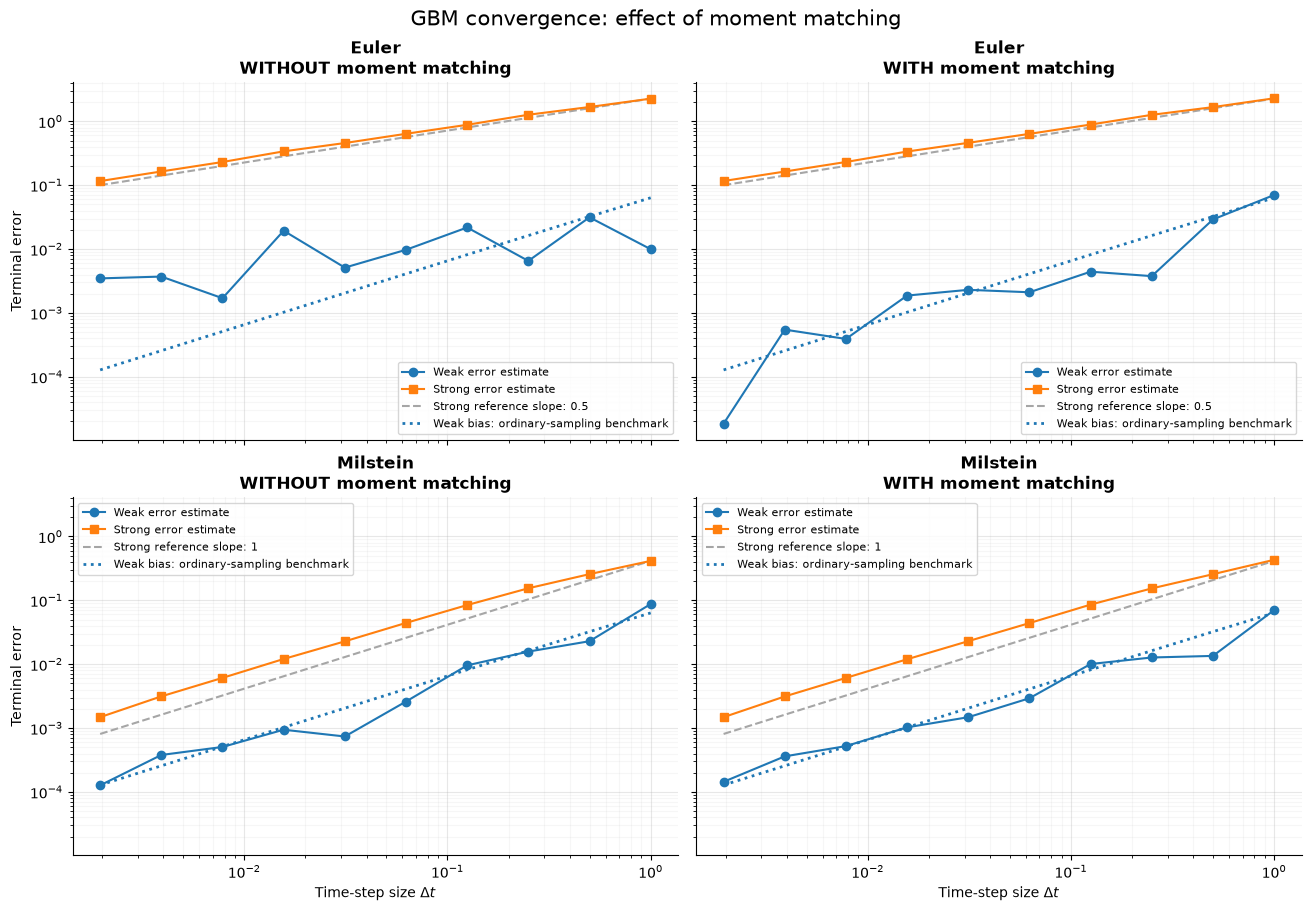

In [ ]:
step_counts = 2 ** np.arange(10)
seed = 1234

paths_no = 2000
terminal_time = 1
interest_rate = 0.05
vol = 0.3
S_0 = 50

results = {}

for scheme in ("euler", "milstein"):
    for matching in (False, True):
        # Reuse the underlying normal draws across all four cases.
        np.random.seed(seed)

        results[(scheme, matching)] = (
            MonteCarloPricing.weak_and_strong_convergence(
                paths_no,
                step_counts,
                terminal_time,
                interest_rate,
                vol,
                S_0,
                scheme=scheme,
                moment_matching=matching,
            )
        )

fig, axes = Plotting.plot_convergence_matching_comparison(
    results,
    S_0,
    interest_rate,
    terminal_time,
)

plt.show()

In [ ]:
path_counts =  [100,1000,5000,10000,50000,100000]
option_type = "call"
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = S_0
step_no =1000
seed=1

results = MonteCarloPricing.mc_convergence(
        path_counts,
        step_no,
        option_type,
        S_0,
        K,
        T,
        r,
        sigma,
        seed,
)

Plotting.print_mc_convergence_table(results)

EUROPEAN OPTION PRICING
Black-Scholes price = 0.7359
Errors = MC price - Black-Scholes price

         N       Exact GBM           Euler        Milstein     Exact error     Euler error  Milstein error
----------------------------------------------------------------------------------------------------------
       100          0.9087          0.9092          0.9087          0.1728          0.1734          0.1728
     1,000          0.7390          0.7389          0.7389          0.0031          0.0031          0.0031
     5,000          0.7440          0.7440          0.7439          0.0081          0.0082          0.0081
    10,000          0.7361          0.7362          0.7361          0.0003          0.0003          0.0002
    50,000          0.7285          0.7285          0.7284         -0.0074         -0.0074         -0.0074
   100,000          0.7320          0.7320          0.7320         -0.0039         -0.0038         -0.0039


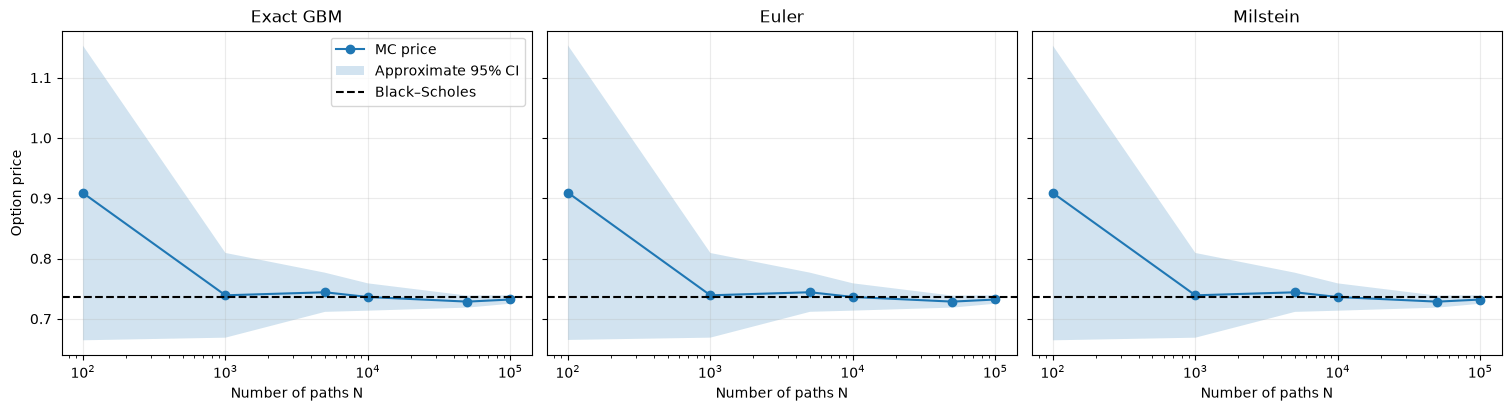

In [93]:
fig, axes = Plotting.plot_mc_convergence(results)
plt.show()

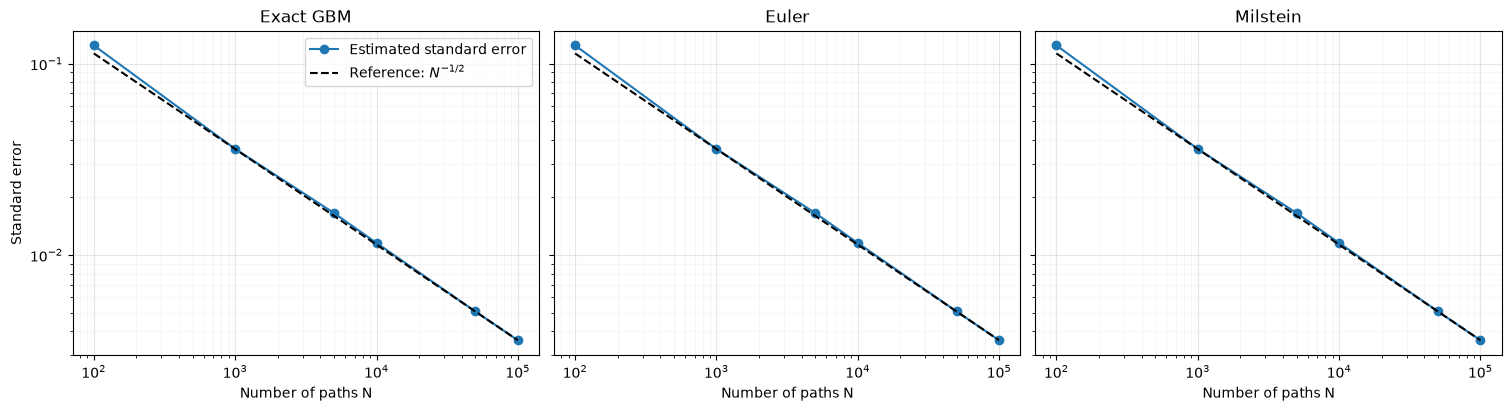

In [94]:
fig, axes = Plotting.plot_mc_standard_error(results)
plt.show()